# Predicting Basil Temperature and Relative Humdity with keras RNN

The goal is to train a Recurrent Neural Network (RNN) on approximately 5 years of meteorological data to forecast temperature and relative humidity for 10 days. The model will base its predictions on a month of data that was not used during training or validation.

I will be using tensorflow.keras.model.sequential to build the neural network.


**Why choose a Recurrent Neural Network (RNN)**
RNNs are particularly well-suited for this task because they excel at processing time-ordered sequences, where the temporal structure and order of data points carry critical information. RNNs can capture temporal dependencies and patterns across sequential data effectively. For this reason, the data is not shuffled before training or prediction, ensuring the temporal order is preserved and exploited for learning.

In [4]:
import tensorflow as tf
import tensorflow.keras as keras
from keras import datasets, layers, models
from keras.layers import Input
from keras import regularizers
from keras.models import Model, Sequential
from keras.layers import Dense, SimpleRNN, LSTM, GRU, Reshape, TimeDistributed, Dropout, BatchNormalization
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
from keras.layers.core import Dropout


# Data preparation

Data can be downloaded from [this](https://www.meteoblue.com/en/weather/archive/export) website. The file contains the 43 attributes I chose to consider. The resolution of the dataset is hourly. The dataset contains data from January 1st 2020 to December 1st 2024. 

Here are a few examples of the features contained in the dataset:

Temperature [2 m elevation corrected],

Growing Degree Days [2 m elevation corrected],

Precipitation Total,    

Relative Humidity [2 m],

Wind Gust, Wind Speed [10 m],

 and so on



In [5]:
import numpy as np
import pandas as pd

data = pd.read_csv('Data/2020-2025.csv',
                        #skiprows=[0,1,2,3,4,5,6,7,8],
                        header=9)

_timestamp = data.iloc[:, 0].astype("datetime64[s]")
_yaer = _timestamp.dt.year.rename("Year")
_month = _timestamp.dt.month.rename("Month")
_day = _timestamp.dt.day.rename("Day")
_hour = _timestamp.dt.hour.rename("Hour")
data.set_index([_yaer, _month, _day, _hour], inplace=True)
data = data.iloc[:, 1:]
i = list(data.columns)
i[0], i[1] = i[1], i[0]

data.head()


Basel Temperature [2 m elevation corrected]  \
Year Month Day Hour                                                
2020 1     1   0                                       -1.489755   
               1                                       -1.729755   
               2                                       -2.069755   
               3                                       -2.359755   
               4                                       -2.589755   

                     Basel Growing Degree Days [2 m elevation corrected]  \
Year Month Day Hour                                                        
2020 1     1   0                                                   0.0     
               1                                                   0.0     
               2                                                   0.0     
               3                                                   0.0     
               4                                                   0.0     

                     Basel Temperature [900 mb]  Basel Temperature [850 mb]  \
Year Month Day Hour                                                           
2020 1     1   0                           7.22                        5.80   
               1                           7.39                        6.10   
               2                           7.67                        6.25   
               3                           7.62                        6.26   
               4                           7.22                        6.14   

                     Basel Temperature [800 mb]  Basel Temperature [700 mb]  \
Year Month Day Hour                                                           
2020 1     1   0                           3.30                        0.05   
               1                           3.72                       -0.09   
               2                           4.01                       -0.32   
               3                           4.20                       -0.53   
               4                           4.32                       -0.68   

                     Basel Precipitation Total  Basel Relative Humidity [2 m]  \
Year Month Day Hour                                                             
2020 1     1   0                           0.0                       90.60191   
               1                           0.0                       90.78249   
               2                           0.0                       91.50318   
               3                           0.0                       91.47641   
               4                           0.0                       91.66238   

                     Basel Snowfall Amount  Basel Wind Gust  ...  \
Year Month Day Hour                                          ...   
2020 1     1   0                       0.0        14.759999  ...   
               1                       0.0        14.040000  ...   
               2                       0.0        12.959999  ...   
               3                       0.0        11.879999  ...   
               4                       0.0        11.879999  ...   

                     Basel Geopotential Height [1000 mb]  \
Year Month Day Hour                                        
2020 1     1   0                                   278.0   
               1                                   273.0   
               2                                   274.0   
               3                                   271.0   
               4                                   269.0   

                     Basel Geopotential Height [850 mb]  \
Year Month Day Hour                                       
2020 1     1   0                                 1603.0   
               1                                 1599.0   
               2                                 1600.0   
               3                                 1597.0   
               4                                 1594.0   

                     Ba

Some data are missing. For the sake of simplicity I chose to drop the whole day which contains a missing data

In [6]:
missing_data = data.shape[0]
data.dropna(inplace=True)
missing_data -= data.shape[0]
print("removed ", missing_data, " rows with missing data.")
data.drop(data.tail(data.shape[0] % 24).index,inplace=True)
#last line drops a few of the last rows in order to align with 24-hour batches

data.head()

removed  72  rows with missing data.


Basel Temperature [2 m elevation corrected]  \
Year Month Day Hour                                                
2020 1     1   0                                       -1.489755   
               1                                       -1.729755   
               2                                       -2.069755   
               3                                       -2.359755   
               4                                       -2.589755   

                     Basel Growing Degree Days [2 m elevation corrected]  \
Year Month Day Hour                                                        
2020 1     1   0                                                   0.0     
               1                                                   0.0     
               2                                                   0.0     
               3                                                   0.0     
               4                                                   0.0     

                     Basel Temperature [900 mb]  Basel Temperature [850 mb]  \
Year Month Day Hour                                                           
2020 1     1   0                           7.22                        5.80   
               1                           7.39                        6.10   
               2                           7.67                        6.25   
               3                           7.62                        6.26   
               4                           7.22                        6.14   

                     Basel Temperature [800 mb]  Basel Temperature [700 mb]  \
Year Month Day Hour                                                           
2020 1     1   0                           3.30                        0.05   
               1                           3.72                       -0.09   
               2                           4.01                       -0.32   
               3                           4.20                       -0.53   
               4                           4.32                       -0.68   

                     Basel Precipitation Total  Basel Relative Humidity [2 m]  \
Year Month Day Hour                                                             
2020 1     1   0                           0.0                       90.60191   
               1                           0.0                       90.78249   
               2                           0.0                       91.50318   
               3                           0.0                       91.47641   
               4                           0.0                       91.66238   

                     Basel Snowfall Amount  Basel Wind Gust  ...  \
Year Month Day Hour                                          ...   
2020 1     1   0                       0.0        14.759999  ...   
               1                       0.0        14.040000  ...   
               2                       0.0        12.959999  ...   
               3                       0.0        11.879999  ...   
               4                       0.0        11.879999  ...   

                     Basel Geopotential Height [1000 mb]  \
Year Month Day Hour                                        
2020 1     1   0                                   278.0   
               1                                   273.0   
               2                                   274.0   
               3                                   271.0   
               4                                   269.0   

                     Basel Geopotential Height [850 mb]  \
Year Month Day Hour                                       
2020 1     1   0                                 1603.0   
               1                                 1599.0   
               2                                 1600.0   
               3                                 1597.0   
               4                                 1594.0   

                     Ba

To enhance generality, I adjusted the resolution to daily by aggregating samples in 24-hour intervals. For each 24-hour batch, the mean, maximum, and minimum values were computed, while precipitation values were summed rather than averaged.

As a result, the total number of features increased as follows:
$$ 43 \rightarrow 42 \times 3 + 1 = 127 $$

This ensures that the temporal resolution aligns with the forecasting objectives while preserving the temporal structure of the data.

In [7]:
#move precipitation in front
columns = data.columns.tolist()
columns = [columns[6]] + columns[:6] + columns[7:]
data = data[columns]

mean_data = pd.DataFrame([[np.mean(data.iloc[i - 23:i + 1, j])
    for j in range(1, data.shape[1])] for i in range(23, data.shape[0], 24)],
    columns=[name + " MEAN" for name in data.columns[1:]])

max_data = pd.DataFrame([[np.max(data.iloc[i - 23:i + 1, j])
    for j in range(1, data.shape[1])] for i in range(23, data.shape[0], 24)],
    columns=[name + " MAX" for name in data.columns[1:]])
min_data = pd.DataFrame([[np.min(data.iloc[i - 23:i + 1, j])
    for j in range(1, data.shape[1])] for i in range(23, data.shape[0], 24)],
    columns=[name + " MIN" for name in data.columns[1:]])

daily_data = pd.DataFrame([[np.sum(data.iloc[i - 23:i + 1, 0])]
    for i in range(23, data.shape[0], 24)], columns=data.columns[0:1])
daily_data = pd.concat([daily_data, mean_data, min_data, max_data], axis=1)

_timestamp = data.index[::24]
_yaer = pd.Series([u[0] for u in _timestamp], name="Year")
_month = pd.Series([u[1] for u in _timestamp], name="Month")
_day = pd.Series([u[2] for u in _timestamp], name="Day")
daily_data.set_index([_yaer, _month, _day], inplace=True)

daily_data.head()

Basel Precipitation Total  \
Year Month Day                              
2020 1     1                          0.0   
           2                          0.0   
           3                          0.9   
           4                          2.2   
           5                          0.0   

                Basel Temperature [2 m elevation corrected] MEAN  \
Year Month Day                                                     
2020 1     1                                           -1.146838   
           2                                            0.077745   
           3                                            5.266079   
           4                                            6.081495   
           5                                            1.993162   

                Basel Growing Degree Days [2 m elevation corrected] MEAN  \
Year Month Day                                                             
2020 1     1                                                  0.0          
           2                                                  0.0          
           3                                                  0.0          
           4                                                  0.0          
           5                                                  0.0          

                Basel Temperature [900 mb] MEAN  \
Year Month Day                                    
2020 1     1                           5.997917   
           2                           3.280833   
           3                           3.737917   
           4                          -0.095000   
           5                          -0.116667   

                Basel Temperature [850 mb] MEAN  \
Year Month Day                                    
2020 1     1                           6.011667   
           2                           2.019583   
           3                           1.993750   
           4                          -1.937917   
           5                          -1.477917   

                Basel Temperature [800 mb] MEAN  \
Year Month Day                                    
2020 1     1                           4.590833   
           2                          -0.366250   
           3                           0.236667   
           4                          -3.825000   
           5                          -2.145000   

                Basel Temperature [700 mb] MEAN  \
Year Month Day                                    
2020 1     1                          -0.886250   
           2                          -6.270000   
           3                          -4.750000   
           4                          -7.416250   
           5                          -4.144583   

                Basel Relative Humidity [2 m] MEAN  \
Year Month Day                                       
2020 1     1                             90.276853   
           2                             93.672080   
           3                             89.174441   
           4                             85.240947   
           5                             87.979175   

                Basel Snowfall Amount MEAN  Basel Wind Gust MEAN  ...  \
Year Month Day                                                    ...   
2020 1     1                           0.0             12.044999  ...   
           2                           0.0             14.864999  ...   
           3                           0.0             25.814999  ...   
           4                           0.0             18.585000  ...   
           5                           0.0             10.950000  ...   

                Basel Geopotential Height [1000 mb] MAX  \
Year Month Day                                            
2020 1     1                                      280.0   
           2                                      265.0   
           3                                      246.0   
           4                                      301.0   
           5 

Since I will want to predict the features:
* $\textit{Basel Temperature [2 m elevation corrected] MEAN}$,
* $\textit{Basel Relative Humidity [2 m] MEAN}$,

I am moving them to ensure their location.


In [8]:
columns = daily_data.columns.tolist()
columns = [columns[1], columns[7]] + columns[:1] + columns[2:7] + columns[8:]
daily_data = daily_data[columns]

daily_data.shape

(1793, 127)

In [9]:
daily_data.head()

Basel Temperature [2 m elevation corrected] MEAN  \
Year Month Day                                                     
2020 1     1                                           -1.146838   
           2                                            0.077745   
           3                                            5.266079   
           4                                            6.081495   
           5                                            1.993162   

                Basel Relative Humidity [2 m] MEAN  Basel Precipitation Total  \
Year Month Day                                                                  
2020 1     1                             90.276853                        0.0   
           2                             93.672080                        0.0   
           3                             89.174441                        0.9   
           4                             85.240947                        2.2   
           5                             87.979175                        0.0   

                Basel Growing Degree Days [2 m elevation corrected] MEAN  \
Year Month Day                                                             
2020 1     1                                                  0.0          
           2                                                  0.0          
           3                                                  0.0          
           4                                                  0.0          
           5                                                  0.0          

                Basel Temperature [900 mb] MEAN  \
Year Month Day                                    
2020 1     1                           5.997917   
           2                           3.280833   
           3                           3.737917   
           4                          -0.095000   
           5                          -0.116667   

                Basel Temperature [850 mb] MEAN  \
Year Month Day                                    
2020 1     1                           6.011667   
           2                           2.019583   
           3                           1.993750   
           4                          -1.937917   
           5                          -1.477917   

                Basel Temperature [800 mb] MEAN  \
Year Month Day                                    
2020 1     1                           4.590833   
           2                          -0.366250   
           3                           0.236667   
           4                          -3.825000   
           5                          -2.145000   

                Basel Temperature [700 mb] MEAN  Basel Snowfall Amount MEAN  \
Year Month Day                                                                
2020 1     1                          -0.886250                         0.0   
           2                          -6.270000                         0.0   
           3                          -4.750000                         0.0   
           4                          -7.416250                         0.0   
           5                          -4.144583                         0.0   

                Basel Wind Gust MEAN  ...  \
Year Month Day                        ...   
2020 1     1               12.044999  ...   
           2               14.864999  ...   
           3               25.814999  ...   
           4               18.585000  ...   
           5               10.950000  ...   

                Basel Geopotential Height [1000 mb] MAX  \
Year Month Day                                            
2020 1     1                                      280.0   
           2                                      265.0   
           3                                      246.0   
           4                                      301.0   
           5                                      301.0   

                Basel Geopotential Height [850 mb] MAX  \
Year Month Day        

Here are the graphs of the mean, minimum and maximum values of the target features.

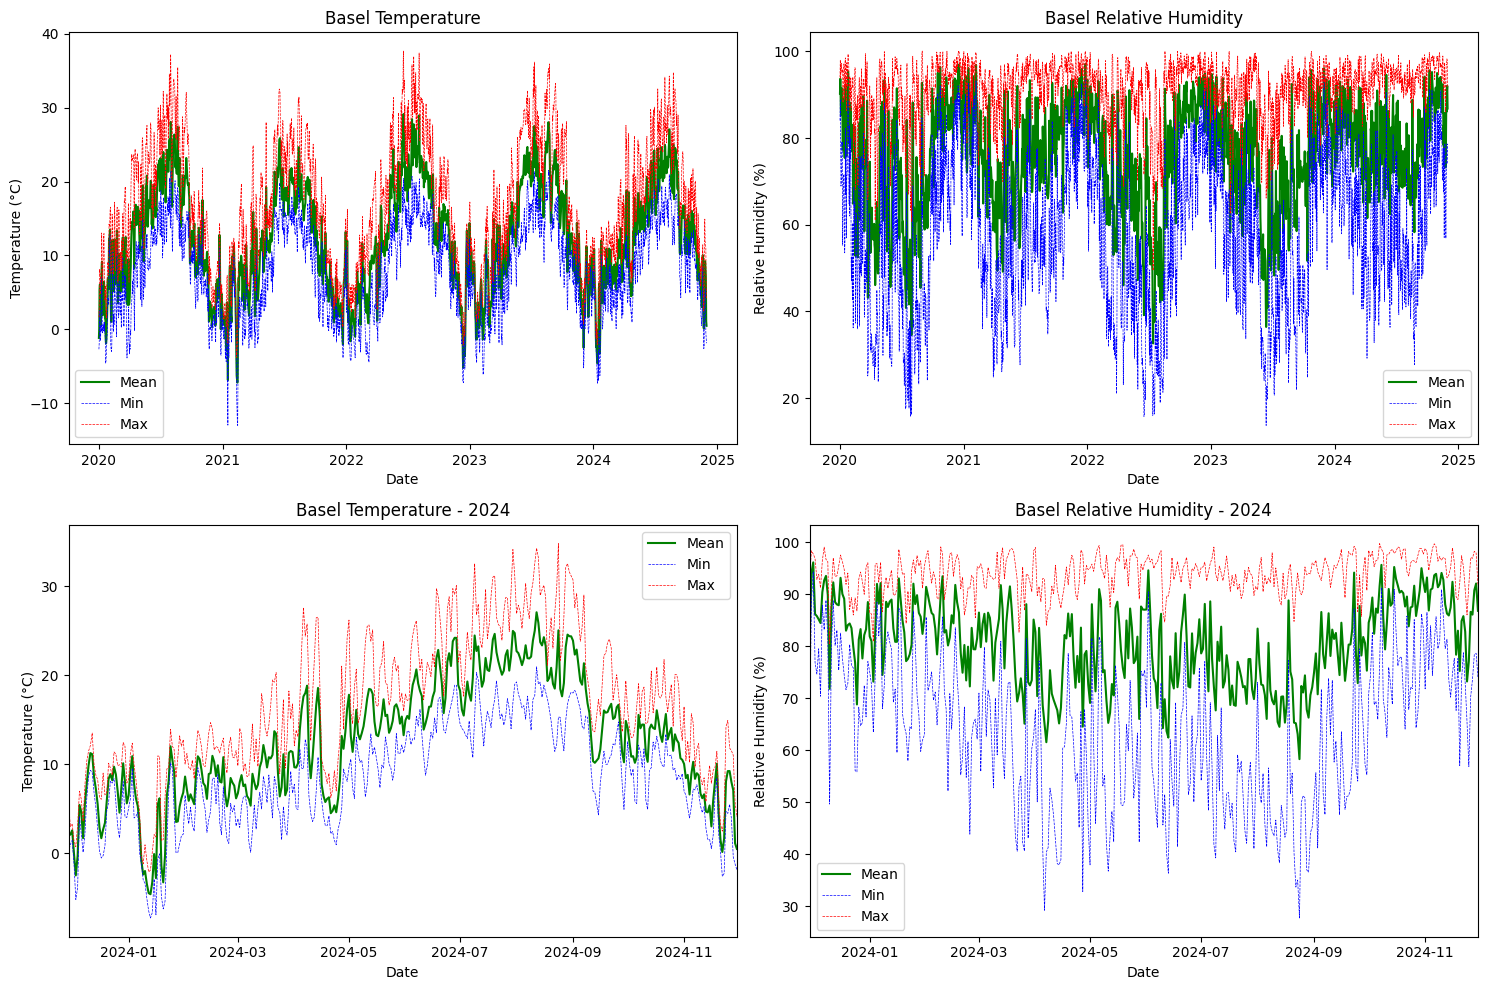

In [10]:
import matplotlib.pyplot as plt
import datetime

index = daily_data.index.values
dates = [datetime.date(year, month, day) for year, month, day in index]

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=False)
axes = axes.flatten()

axes[0].plot(dates, daily_data['Basel Temperature [2 m elevation corrected] MEAN'], 'g', label='Mean')
axes[0].plot(dates, daily_data['Basel Temperature [2 m elevation corrected] MIN'], '--b', linewidth=0.5, label='Min')
axes[0].plot(dates, daily_data['Basel Temperature [2 m elevation corrected] MAX'], '--r', linewidth=0.5, label='Max')
axes[0].set_title('Basel Temperature')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Temperature (°C)')
axes[0].legend()

axes[1].plot(dates, daily_data['Basel Relative Humidity [2 m] MEAN'], 'g', label='Mean')
axes[1].plot(dates, daily_data['Basel Relative Humidity [2 m] MIN'], '--b', linewidth=0.5, label='Min')
axes[1].plot(dates, daily_data['Basel Relative Humidity [2 m] MAX'], '--r', linewidth=0.5, label='Max')
axes[1].set_title('Basel Relative Humidity')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Relative Humidity (%)')
axes[1].legend()

last_data = daily_data.tail(365)
last_index = last_data.index.values
last_dates = [datetime.date(year, month, day) for year, month, day in last_index]

axes[2].plot(last_dates, last_data['Basel Temperature [2 m elevation corrected] MEAN'], 'g', label='Mean')
axes[2].plot(last_dates, last_data['Basel Temperature [2 m elevation corrected] MIN'], '--b', linewidth=0.5, label='Min')
axes[2].plot(last_dates, last_data['Basel Temperature [2 m elevation corrected] MAX'], '--r', linewidth=0.5, label='Max')
axes[2].set_title('Basel Temperature - 2024')
axes[2].set_xlabel('Date')
axes[2].set_ylabel('Temperature (°C)')
axes[2].set_xlim([min(last_dates), max(last_dates)])
axes[2].legend()

axes[3].plot(last_dates, last_data['Basel Relative Humidity [2 m] MEAN'], 'g', label='Mean')
axes[3].plot(last_dates, last_data['Basel Relative Humidity [2 m] MIN'], '--b', linewidth=0.5, label='Min')
axes[3].plot(last_dates, last_data['Basel Relative Humidity [2 m] MAX'], '--r', linewidth=0.5, label='Max')
axes[3].set_title('Basel Relative Humidity - 2024')
axes[3].set_xlabel('Date')
axes[3].set_ylabel('Relative Humidity (%)')
axes[3].set_xlim([min(last_dates), max(last_dates)])
axes[3].legend()

plt.tight_layout()
plt.show()


# Data Formatting

First of all, data are separated in validation and training data.

In [11]:
split_index = int(0.9 * daily_data.shape[0])

train = daily_data.iloc[:split_index]
validation = daily_data.iloc[split_index:]

The data are sparse, with features such as relative humidity and temperature running on significantly different scales. To address this, all features were standardized before being fed into the neural network. Standardization was performed by subtracting the mean and scaling to unit variance.
$$ z = \frac{x - \mu}{\sigma} $$
Here, μ and σ represent the mean and standard deviation, respectively, computed across the 1,576 or 176 data points (depending on the dataset partition).

*note*:  parameters of nomalization are found only considering the *training set*, they are not recalculated on the *test set*.

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

trainSTD = scaler.fit_transform(train)
valSTD = scaler.transform(validation)


In order to feed the data to a keras.sequential neaural network data need to be formatted in the right shape. Keras accept data with the following shape:

$$
 \quad (\textit{num\_samples}, \textit{timesteps}, \textit{features})
$$

To achieve this a sliding window has been defined in order to create 127 different sequences,
* each of size 31 (timestep) for features,
* each of size 10 (timestep) for labels,

For each column of the desing matrix the i-th cycle appends to an X-list values from i to i+31 of the column.
The y to be chosen to compute cost functions during training will then be the following 10 values to those just appended to the X-list.

What has been done is the following:

The desing matrix X is now a 1793 by 127 matrix. Data will be split with the following ratios and shapes for training.

| Set           | Shape                     |
|:-------------:|:-------------------------:|
| X_train       | (1576, 31, 127)       |
| y_train       | (176, 10, 127)       |
| X_validation  | (1576, 31, 127)       |
| y_validation  | (176, 1, 127)        |

target values have the showed shape so that the goal of predicting 10 timpesteps, *i.e.* days, is met.

In [13]:
sequence_length = 31  
forecast_steps = 10   
num_features = daily_data.shape[1]

#Training set
X_train = []
y_train = []
for i in range(len(trainSTD) - sequence_length - forecast_steps):
    X_train.append(trainSTD[i:i + sequence_length])

    y_train.append(trainSTD[i + sequence_length:i + sequence_length + forecast_steps])

X_train = np.array(X_train)
y_train = np.array(y_train)

#Validation set
X_val = []
y_val = []
for i in range(len(valSTD) - sequence_length - forecast_steps):
    X_val.append(valSTD[i:i + sequence_length])

    y_val.append(valSTD[i + sequence_length:i + sequence_length + forecast_steps])

X_val = np.array(X_val)
y_val = np.array(y_val)



print(X_train.shape, X_val.shape, y_train.shape, y_val.shape)


(1572, 31, 127) (139, 31, 127) (1572, 10, 127) (139, 10, 127)


In the following part cell I am loading new data on which the RNN will produce predictions.

The loaded data are from December 1st 2024 to January 1st 2025.

The same operations of daily timescale, clensing and standardization have been performed

In [14]:
dataPRED = pd.read_csv('Data/predict_month.csv',
                        #skiprows=[0,1,2,3,4,5,6,7,8],
                        header=9)

_timestamp = dataPRED.iloc[:, 0].astype("datetime64[s]")
_yaer = _timestamp.dt.year.rename("Year")
_month = _timestamp.dt.month.rename("Month")
_day = _timestamp.dt.day.rename("Day")
_hour = _timestamp.dt.hour.rename("Hour")
dataPRED.set_index([_yaer, _month, _day, _hour], inplace=True)
dataPRED = dataPRED.iloc[:, 1:]
i = list(dataPRED.columns)
i[0], i[1] = i[1], i[0]


dataPRED.drop(dataPRED.tail(dataPRED.shape[0] % 24).index,inplace=True)

#move precipitation in front
columns = dataPRED.columns.tolist()
columns = [columns[6]] + columns[:6] + columns[7:]
dataPRED = dataPRED[columns]



mean_data = pd.DataFrame([[np.mean(dataPRED.iloc[i - 23:i + 1, j])
    for j in range(1, dataPRED.shape[1])] for i in range(23, dataPRED.shape[0], 24)],
    columns=[name + " MEAN" for name in dataPRED.columns[1:]])
max_data = pd.DataFrame([[np.max(dataPRED.iloc[i - 23:i + 1, j])
    for j in range(1, dataPRED.shape[1])] for i in range(23, dataPRED.shape[0], 24)],
    columns=[name + " MAX" for name in dataPRED.columns[1:]])
min_data = pd.DataFrame([[np.min(dataPRED.iloc[i - 23:i + 1, j])
    for j in range(1, dataPRED.shape[1])] for i in range(23, dataPRED.shape[0], 24)],
    columns=[name + " MIN" for name in dataPRED.columns[1:]])

daily_dataPRED = pd.DataFrame([[np.sum(dataPRED.iloc[i - 23:i + 1, 0])]
    for i in range(23, dataPRED.shape[0], 24)], columns=dataPRED.columns[0:1])
daily_dataPRED = pd.concat([daily_dataPRED, mean_data, min_data, max_data], axis=1)

_timestamp = dataPRED.index[::24]
_yaer = pd.Series([u[0] for u in _timestamp], name="Year")
_month = pd.Series([u[1] for u in _timestamp], name="Month")
_day = pd.Series([u[2] for u in _timestamp], name="Day")
daily_dataPRED.set_index([_yaer, _month, _day], inplace=True)

columns = daily_dataPRED.columns.tolist()
columns = [columns[1], columns[7]] + columns[:1] + columns[2:7] + columns[8:]
daily_dataPRED = daily_dataPRED[columns]



daily_dataPRED.head()


Basel Temperature [2 m elevation corrected] MEAN  \
Year Month Day                                                     
2024 12    1                                            1.437745   
           2                                            7.454412   
           3                                            6.241912   
           4                                            4.146495   
           5                                            2.841079   

                Basel Relative Humidity [2 m] MEAN  Basel Precipitation Total  \
Year Month Day                                                                  
2024 12    1                             88.456733                        0.0   
           2                             89.124713                        5.2   
           3                             86.137144                        0.9   
           4                             87.523285                        0.6   
           5                             87.750596                        1.6   

                Basel Growing Degree Days [2 m elevation corrected] MEAN  \
Year Month Day                                                             
2024 12    1                                             0.000000          
           2                                             0.001824          
           3                                             0.000000          
           4                                             0.000000          
           5                                             0.000000          

                Basel Temperature [900 mb] MEAN  \
Year Month Day                                    
2024 12    1                           7.212500   
           2                           6.883333   
           3                           0.855000   
           4                          -1.427083   
           5                           0.948750   

                Basel Temperature [850 mb] MEAN  \
Year Month Day                                    
2024 12    1                           7.096667   
           2                           4.077917   
           3                          -2.217083   
           4                          -4.994167   
           5                           0.219167   

                Basel Temperature [800 mb] MEAN  \
Year Month Day                                    
2024 12    1                           4.737500   
           2                           1.173750   
           3                          -5.224583   
           4                          -7.727083   
           5                          -1.041250   

                Basel Temperature [700 mb] MEAN  Basel Snowfall Amount MEAN  \
Year Month Day                                                                
2024 12    1                          -1.791667                         0.0   
           2                          -5.489167                         0.0   
           3                         -11.134583                         0.0   
           4                         -11.805417                         0.0   
           5                          -5.625000                         0.0   

                Basel Wind Gust MEAN  ...  \
Year Month Day                        ...   
2024 12    1                  15.570  ...   
           2                  19.590  ...   
           3                  15.435  ...   
           4                  10.830  ...   
           5                  21.375  ...   

                Basel Geopotential Height [1000 mb] MAX  \
Year Month Day                                            
2024 12    1                                      235.0   
           2                                      192.0   
           3                                      188.0   
           4                                      247.0   
           5                                      243.0   

                Basel Geopotential Height [850 mb] MAX  \
Year Month Day        

In [15]:
daily_dataPRED.shape

(31, 127)

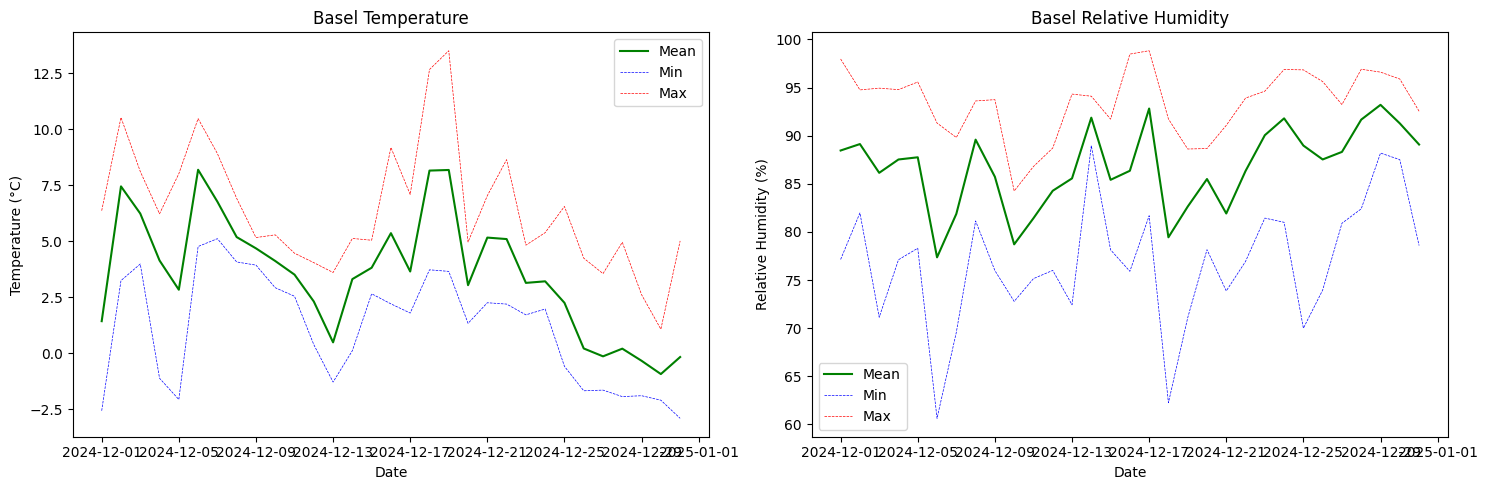

In [16]:
dataPRED_standardized = scaler.transform(daily_dataPRED)

toBePred = dataPRED_standardized[np.newaxis, :]

indexPRED = daily_dataPRED.index.values
datesPRED = [datetime.date(year, month, day) for year, month, day in indexPRED]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))
axes = axes.flatten()

axes[0].plot(datesPRED, daily_dataPRED['Basel Temperature [2 m elevation corrected] MEAN'], 'g', label='Mean')
axes[0].plot(datesPRED, daily_dataPRED['Basel Temperature [2 m elevation corrected] MIN'], '--b', linewidth=0.5, label='Min')
axes[0].plot(datesPRED, daily_dataPRED['Basel Temperature [2 m elevation corrected] MAX'], '--r', linewidth=0.5, label='Max')
axes[0].set_title('Basel Temperature')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Temperature (°C)')
axes[0].legend()
axes[1].plot(datesPRED, daily_dataPRED['Basel Relative Humidity [2 m] MEAN'], 'g', label='Mean')
axes[1].plot(datesPRED, daily_dataPRED['Basel Relative Humidity [2 m] MIN'], '--b', linewidth=0.5, label='Min')
axes[1].plot(datesPRED, daily_dataPRED['Basel Relative Humidity [2 m] MAX'], '--r', linewidth=0.5, label='Max')
axes[1].set_title('Basel Relative Humidity')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Relative Humidity (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

# Recurrent Neural Network Implementations

An RNN is a type of neural network that uses its outputs as inputs for the following timestep. This recurrence allows the network to process sequential data and retain information from previous timesteps, making it well-suited for tasks like time-series analysis.

By unrolling the RNN through time, it becomes clear that its structure and components are fundamentally similar to simpler feedforward neural networks (FFNN), with the addition of recurrent connections that enable a sort of temporal memory.

To increase model complexity and improve learning capabilities, multiple RNN layers can be stacked, creating a deep RNN. This layering enhances the model's ability to capture intricate patterns in the data.

Keras provides a variety of RNN layers, such as SimpleRNN, LSTM, and GRU, each designed to address specific challenges like long-term dependencies and training stability.
* SimpleRNN: The most basic recurrent layer. It processes inputs sequentially, with a single hidden state passed between timesteps. Suffers from vanishing/exploding gradient problems, making it unsuitable for modeling long-term dependencies in sequences
* LSTM: a type of RNN designed to solve the vanishing gradient problem. It uses gates (INPUT, FORGET, OUTPUT) to control the flow of information and maintain long-term dependencies.
* GRU: a simplefied version of LSTM. Different gating system (UPDATE, RESET).

Now I shall implement and compile the different RNN using keras packages.

The objective is to implement RNNs which differs in complexity. 

The parameters that will be taken into account in order to make observations on the RNNs performances are:
+ validation loss (desent per timestep, overtfitting, underfitting),
+ computational cost,
+ predictional accuracy.

RNNs properties that will be changed in order to observe different performances are:
+ Complexity:
    + Number of layers, 
    + number of nodes per layer,
+ Regularizations:
    + Type of regularizer (Dropout, l2)
    + Regularizer parameter

**What follows is a first attempt.**

Models are fit using an adam optimizer with an decay of learning_rate/epochs. Even if Adam already has an adaptable learning rate suited for each feature, I decided to add a manual tweak of the global learning rate with patience 3 in order to help the convergence in the final part of training. 

The fit is stopped by an EarlyStopping call back monitoring the validation loss with patience 5.

Activation functions of SimpleRNN is the default hyperbolic tangent.

Activation function of the final dense layer is the default linear.

In [17]:
from keras import regularizers
from keras.models import Sequential
from keras.layers import SimpleRNN, LSTM, Dense, Dropout, Reshape, TimeDistributed

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout, TimeDistributed, Reshape, BatchNormalization
from tensorflow.keras import regularizers

model_simpleRNN = Sequential([
    SimpleRNN(256, return_sequences=True, input_shape=(31, 127), 
              kernel_regularizer=regularizers.l2(0.01)),
    BatchNormalization(),
    Dropout(0.2),
    SimpleRNN(124, return_sequences=True, 
              kernel_regularizer=regularizers.l2(0.01), 
              recurrent_dropout=0.2),
    BatchNormalization(),
    SimpleRNN(124, return_sequences=True, 
              kernel_regularizer=regularizers.l2(0.01), 
              recurrent_dropout=0.2),
    BatchNormalization(),
    SimpleRNN(124, return_sequences=False, 
              kernel_regularizer=regularizers.l2(0.01)),
    Dropout(0.2),
    Dense(1270),
    Reshape((10, 127)), 
    TimeDistributed(Dense(127))
])


LR = 10e-5
EPOCHS = 50
opt = Adam(learning_rate=LR, decay=LR/EPOCHS)
model_simpleRNN.compile(optimizer=opt, loss='mse')
model_simpleRNN.summary()

history = model_simpleRNN.fit(
    X_train, 
    y_train, 
    epochs= EPOCHS, 
    batch_size= 32, 
    validation_data=(X_val, y_val), 
    callbacks=[
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
    ]
)

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn_2 (SimpleRNN)    (None, 31, 256)           98304     
                                                                 
 batch_normalization_4 (Batc  (None, 31, 256)          1024      
 hNormalization)                                                 
                                                                 
 dropout_4 (Dropout)         (None, 31, 256)           0         
                                                                 
 simple_rnn_3 (SimpleRNN)    (None, 31, 124)           47244     
                                                                 
 batch_normalization_5 (Batc  (None, 31, 124)          496       
 hNormalization)                                                 
                                                                 
 simple_rnn_4 (SimpleRNN)    (None, 31, 124)          

5/5 [==============================] - 0s 19ms/step - loss: 1.0324


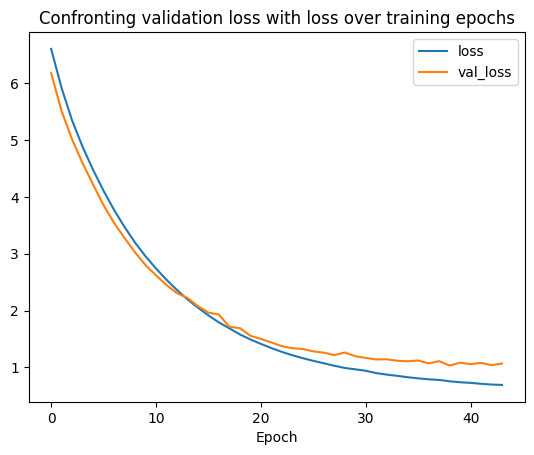

,Train Score,Test Score
sequential_4,0.72179,1.032408


In [18]:
for label in ["loss","val_loss"]:
    plt.plot(history.history[label],label=label)

plt.xlabel("Epoch")
plt.title("Confronting validation loss with loss over training epochs")

Score = pd.DataFrame(
    [[model_simpleRNN.evaluate(X_train, y_train), model_simpleRNN.evaluate(X_val, y_val)]],
    columns=["Train Score", "Test Score"], index=[model_simpleRNN.name]
)

plt.legend()
plt.show()

pd.DataFrame(Score)

**Observations:**
* validation loss does not improve after roughly epoch 40. 
* validation loss is not increasing either. That is beacause it can't, since an eralystopping callback is implemented, but it could be an indicator that the model's complexity could be increased.
* Loss is consistently reducing, therfore the model is not underfitting either.

**Partial conclusions:**
* A process of trial and error in tweaking the model complexity could benefit the convergence.
* Since the validation loss is not increasing some complexity can be added to the model.

Before continuing let me visualize the predictions. Note that in order to visualize the correct numerical values I run inverse.tranform on the prediction array.

In [19]:
predictions = model_simpleRNN.predict(toBePred)
predictionsDest = scaler.inverse_transform(np.array(predictions)[0, :, :])

myTEMPandHumid = np.array(predictionsDest)[:,[0, 1]]

1/1 [==============================] - 1s 591ms/step


In [20]:
true = pd.read_csv('Data/true.csv',
                        #skiprows=[0,1,2,3,4,5,6,7,8],
                        header=9)

_timestamp = true.iloc[:, 0].astype("datetime64[s]")
_yaer = _timestamp.dt.year.rename("Year")
_month = _timestamp.dt.month.rename("Month")
_day = _timestamp.dt.day.rename("Day")
_hour = _timestamp.dt.hour.rename("Hour")
true.set_index([_yaer, _month, _day, _hour], inplace=True)
true = true.iloc[:, 1:]
i = list(true.columns)
i[0], i[1] = i[1], i[0]



missing_datatrue = true.shape[0]
true.dropna(inplace=True)
missing_datatrue -= true.shape[0]
true.drop(true.tail(true.shape[0] % 24).index,inplace=True)

mean_datatrue = pd.DataFrame([[np.mean(true.iloc[i - 23:i + 1, j])
    for j in range(0, true.shape[1])] for i in range(23, true.shape[0], 24)],
    columns=[name + " MEAN" for name in true.columns[0:]])


max_datatrue = pd.DataFrame([[np.max(true.iloc[i - 23:i + 1, j])
    for j in range(0, true.shape[1])] for i in range(23, true.shape[0], 24)],
    columns=[name + " MAX" for name in true.columns[0:]])

min_datatrue = pd.DataFrame([[np.min(true.iloc[i - 23:i + 1, j])
    for j in range(0, true.shape[1])] for i in range(23, true.shape[0], 24)],
    columns=[name + " MIN" for name in true.columns[0:]])
'''
'''
daily_true = pd.concat([mean_datatrue, min_datatrue, max_datatrue], axis=1)
# set Index
_timestamp = true.index[::24]
_yaer = pd.Series([u[0] for u in _timestamp], name="Year")
_month = pd.Series([u[1] for u in _timestamp], name="Month")
_day = pd.Series([u[2] for u in _timestamp], name="Day")
daily_true.set_index([_yaer, _month, _day], inplace=True)

columns = daily_true.columns.tolist()
daily_true = daily_true[columns]

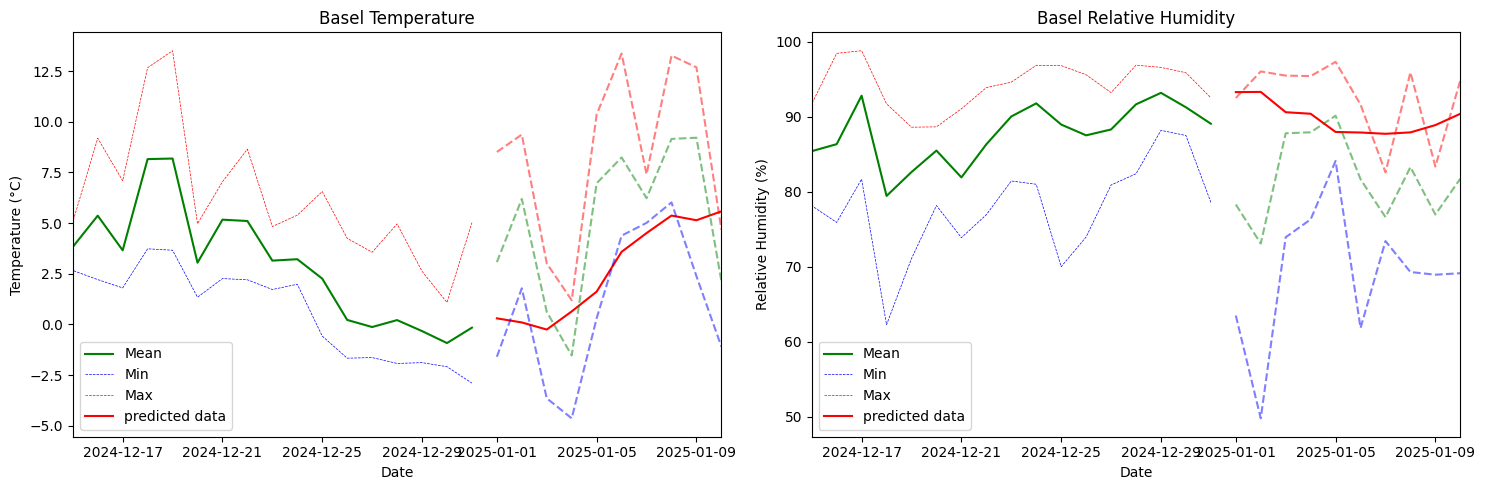

5/5 [==============================] - 0s 17ms/step - loss: 1.0324


In [21]:
import datetime

index = daily_dataPRED.index.values
dates = [datetime.date(year, month, day) for year, month, day in index]

indexTrue = daily_true.index.values
datesPRED = [datetime.date(year, month, day) for year, month, day in indexTrue]


fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
axes = axes.flatten()

axes[0].plot(dates, daily_dataPRED['Basel Temperature [2 m elevation corrected] MEAN'], 'g', label='Mean')
axes[0].plot(dates, daily_dataPRED['Basel Temperature [2 m elevation corrected] MIN'], '--b', linewidth=0.5, label='Min')
axes[0].plot(dates, daily_dataPRED['Basel Temperature [2 m elevation corrected] MAX'], '--r', linewidth=0.5, label='Max')
axes[0].set_title('Basel Temperature')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Temperature (°C)')
axes[0].legend()
axes[1].plot(dates, daily_dataPRED['Basel Relative Humidity [2 m] MEAN'], 'g', label='Mean')
axes[1].plot(dates, daily_dataPRED['Basel Relative Humidity [2 m] MIN'], '--b', linewidth=0.5, label='Min')
axes[1].plot(dates, daily_dataPRED['Basel Relative Humidity [2 m] MAX'], '--r', linewidth=0.5, label='Max')
axes[1].set_title('Basel Relative Humidity')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Relative Humidity (%)')
axes[1].legend()

axes[0].plot(datesPRED, myTEMPandHumid[:,0],'-r', label="predicted data")
axes[1].plot(datesPRED, myTEMPandHumid[:,1],'-r', label="predicted data")

axes[0].plot(datesPRED, daily_true.values[:,0],'--g', alpha=.5)
axes[0].plot(datesPRED, daily_true.values[:,2],'--b', alpha=.5)
axes[0].plot(datesPRED, daily_true.values[:,4],'--r', alpha=.5)

axes[1].plot(datesPRED, daily_true.values[:,1],'--g', alpha=.5)
axes[1].plot(datesPRED, daily_true.values[:,3],'--b', alpha=.5)
axes[1].plot(datesPRED, daily_true.values[:,5],'--r', alpha=.5)

axes[0].legend()
axes[1].legend()

start_date = datetime.date(2024, 12, 15)
axes[0].set_xlim([start_date, max(datesPRED)])
axes[1].set_xlim([start_date, max(datesPRED)])

plt.tight_layout()
plt.show()

Score = pd.DataFrame(
    [[model_simpleRNN.evaluate(X_train, y_train), model_simpleRNN.evaluate(X_val, y_val)]],
    columns=["Train Score", "Test Score"], index=[model_simpleRNN.name]
)


It can be noted how the model is not able to follow the real fluctuations of temperature and humidity. While it correctly predicts the direction of change (e.g., increasing temperature or decreasing relative humidity), the magnitude of these changes tends to be underestimated.

# Trying different models

In [22]:
LR = 10e-5
EPOCHS = 50
opt = Adam(learning_rate=LR, decay=LR/EPOCHS)


model_shallowRNN = Sequential([
    SimpleRNN(300, return_sequences=False, input_shape=(31, 127)),
    Dense(1270),
    Reshape((10, 127)),
    TimeDistributed(Dense(127)) 
]) 


model_LSTM = Sequential([
    LSTM(100, return_sequences=False, input_shape=(31, 127), kernel_regularizer=regularizers.l2(0.01)),
    BatchNormalization(),
    Dropout(0.2),
    Dense(1270),
    Reshape((10, 127)),
    TimeDistributed(Dense(127)) 
]) 


model_GRU = Sequential([
    GRU(256, return_sequences=False, input_shape=(31, 127), kernel_regularizer=regularizers.l2(0.01)),
    BatchNormalization(),
    Dropout(0.2),
    Dense(1270),
    Reshape((10, 127)),
    TimeDistributed(Dense(127)) 
])


model_complex = Sequential([
    SimpleRNN(512, return_sequences=True, input_shape=(31, 127), kernel_regularizer=regularizers.l2(0.01)),
    BatchNormalization(),
    Dropout(0.2),
    GRU(50, return_sequences=False),
    BatchNormalization(),
    Dropout(0.2),
    Dense(1270),
    Reshape((10, 127)),
    TimeDistributed(Dense(127)) 
])

In [23]:
LR = 10e-5
opt = Adam(learning_rate=LR, decay=LR/EPOCHS)
model_shallowRNN.compile(optimizer=opt, loss='mse')
model_shallowRNN.summary()
hist_shallowRNN = model_shallowRNN.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_val, y_val),
                                      callbacks=[
                                      keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                                      keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
                                      ])

LR = 10e-5
opt = Adam(learning_rate=LR, decay=LR/EPOCHS)
model_LSTM.compile(optimizer=opt, loss='mse')
model_LSTM.summary()
histl_LSTM = model_LSTM.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_val, y_val),
                                      callbacks=[
                                      keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                                      keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
                                      ])

LR = 10e-5   
opt = Adam(learning_rate=LR, decay=LR/EPOCHS)     
model_GRU.compile(optimizer=opt, loss='mse')
model_GRU.summary()
hist_GRU = model_GRU.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_val, y_val),
                                      callbacks=[
                                      keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                                      keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
                                      ])

LR = 10e-5
opt = Adam(learning_rate=LR, decay=LR/EPOCHS)
model_complex.compile(optimizer=opt, loss='mse')
model_complex.summary()
hist_complex = model_complex.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_val, y_val),
                                      callbacks=[
                                      keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                                      keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
                                      ])


Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn_6 (SimpleRNN)    (None, 300)               128400    
                                                                 
 dense_10 (Dense)            (None, 1270)              382270    
                                                                 
 reshape_5 (Reshape)         (None, 10, 127)           0         
                                                                 
 time_distributed_5 (TimeDis  (None, 10, 127)          16256     
 tributed)                                                       
                                                                 
Total params: 526,926
Trainable params: 526,926
Non-trainable params: 0
_________________________________________________________________
Epoch 1/50
50/50 [==============================] - 2s 31ms/step - loss: 0.9585 - val_loss: 0.7714 - lr: 1.0000e-0

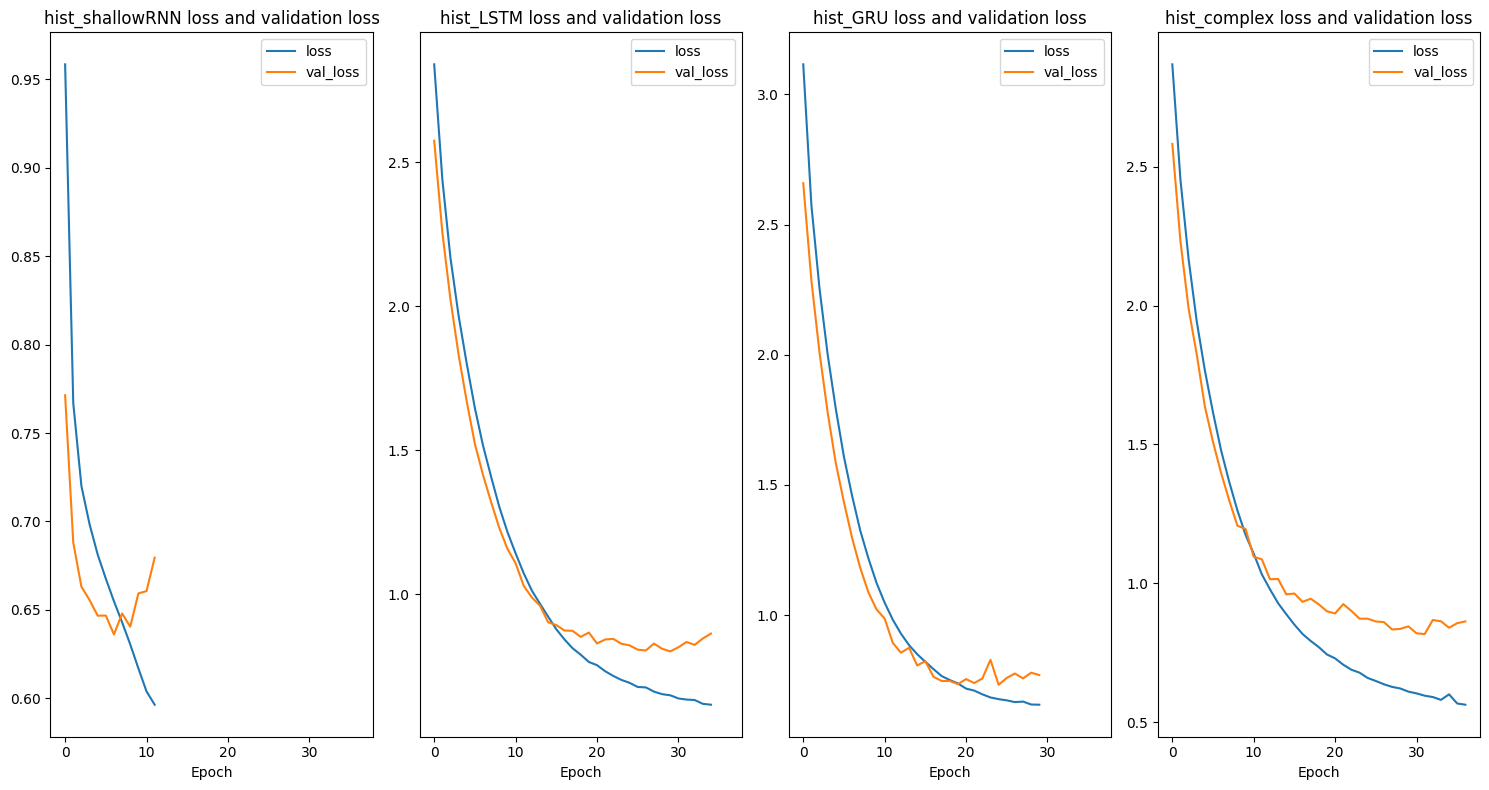

5/5 [==============================] - 0s 16ms/step - loss: 0.8169
              Train Score  Test Score
sequential_5     0.645969    0.636103
              Train Score  Test Score
sequential_6     0.607392    0.801345
              Train Score  Test Score
sequential_7     0.625175    0.732254
              Train Score  Test Score
sequential_8     0.541259    0.816853


In [24]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(15, 8), sharex=True)

axes = axes.flatten()

for label in ["loss","val_loss"]:
    axes[0].plot(hist_shallowRNN.history[label],label=label)
axes[0].set_title('hist_shallowRNN loss and validation loss')

for label in ["loss","val_loss"]:
    axes[1].plot(histl_LSTM.history[label],label=label)
axes[1].set_title('hist_LSTM loss and validation loss')

for label in ["loss","val_loss"]:
    axes[2].plot(hist_GRU.history[label],label=label)
axes[2].set_title('hist_GRU loss and validation loss')

for label in ["loss","val_loss"]:
    axes[3].plot(hist_complex.history[label],label=label)
axes[3].set_title('hist_complex loss and validation loss')


axes[0].legend()
axes[0].set_xlabel('Epoch')

axes[1].legend()
axes[1].set_xlabel('Epoch')

axes[2].legend()
axes[2].set_xlabel('Epoch')

axes[3].legend()
axes[3].set_xlabel('Epoch')

plt.tight_layout()
plt.show()

Scores = []
for model in [model_shallowRNN, model_LSTM, model_GRU, model_complex]:
    Scores.append(pd.DataFrame(
        [[model.evaluate(X_train, y_train), model.evaluate(X_val, y_val)]],
        columns=["Train Score", "Test Score"], index=[model.name]
    ))
for i in range(len(Scores)):
    print(pd.DataFrame(Scores[i]))

Results do not significantly improve from the simple deep RNN implemented above.

+ **Shallow RNN**
This RNN had 526926 parameters and no Normalization. It stopped after only epochs thanks to the earlystoppage callback.
+ **LSTM**
The Long-Short Term memory layer did not improve to decrease the validation loss. On the contrary, as the trining loss continued to decrease the validation loss started decreasing its descent around epoch 15 manifesting the model overfit.
+ **GRU**
Performed better than the network with the LSTM layer, decreasing the validation loss consistently for 25 epochs with fluctuations allowed by the patience parameters.
+ **Complex RNN**
Managed to decrease the validation loss for 35 epochs, reaching a performance confrontable with the network with a GRU layer.

In [25]:
predictions= []
for model in [model_shallowRNN, model_LSTM, model_GRU, model_complex]:
    predictions.append(model.predict(toBePred))

1/1 [==============================] - 0s 413ms/step


In order to read correct numerical values data need to be brought back to the right scale.

In [26]:
predARR = np.array(predictions)
predictionsDest = []
for i in range(4):
    predictionsDest.append(scaler.inverse_transform(predARR[i,0,:,:]))

myTEMPandHumid = np.array(predictionsDest)[:,:,[0, 1]]

Let us see how it did!

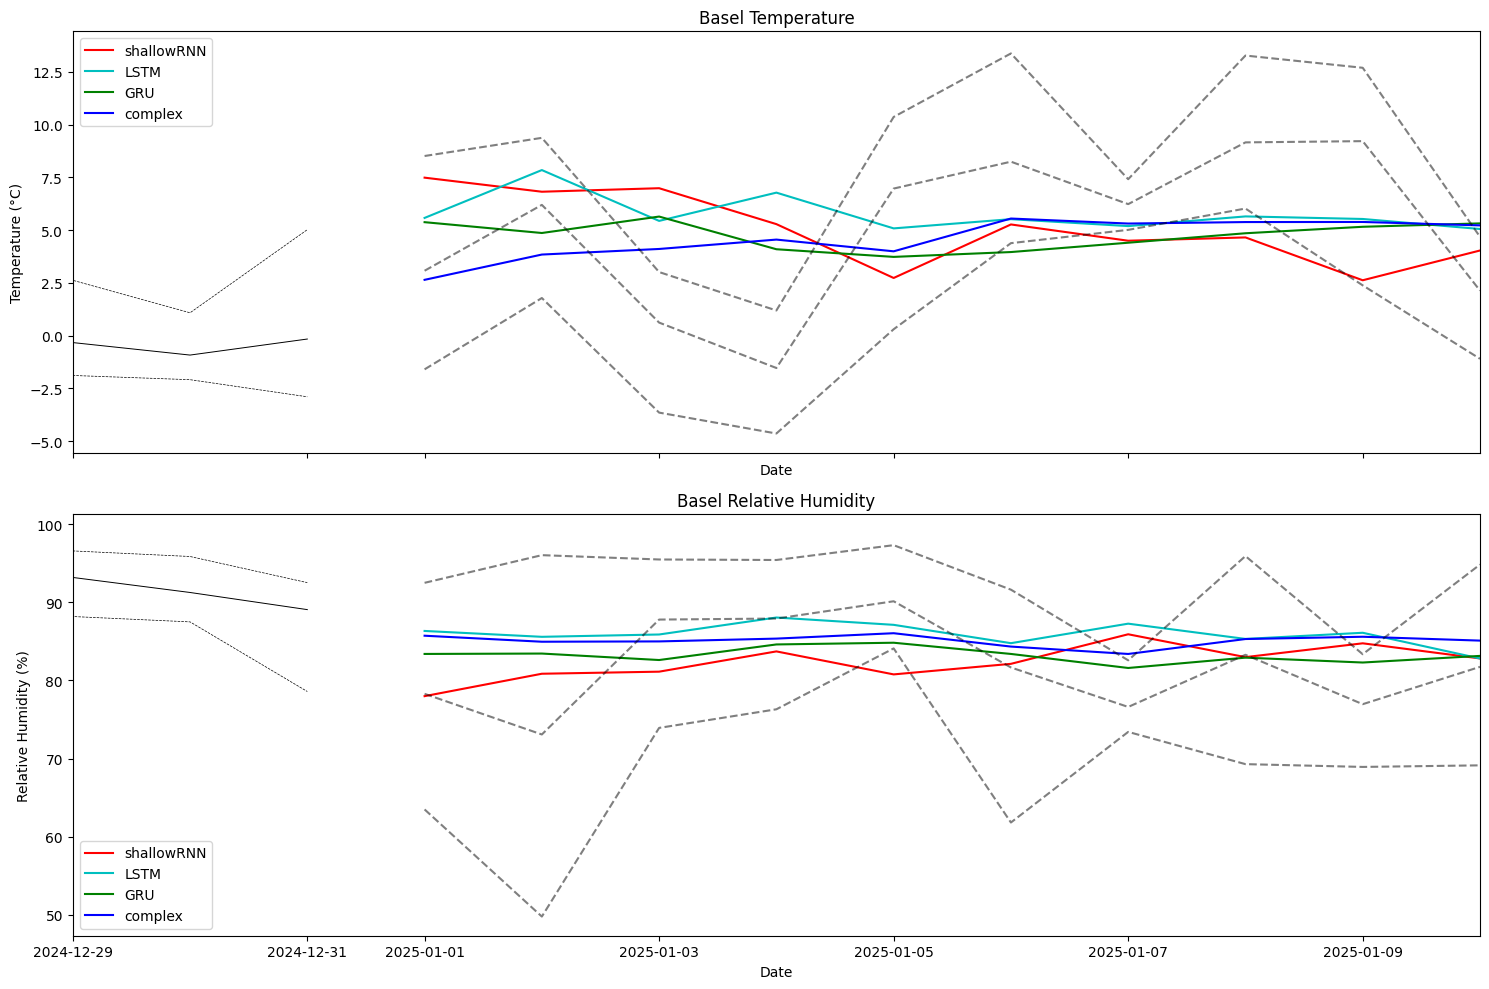

In [27]:
import datetime
index = daily_dataPRED.index.values
dates = [datetime.date(year, month, day) for year, month, day in index]

indexTrue = daily_true.index.values
datesPRED = [datetime.date(year, month, day) for year, month, day in indexTrue]


fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(15,10), sharex=True)
axes = axes.flatten()

axes[0].plot(dates, daily_dataPRED['Basel Temperature [2 m elevation corrected] MEAN'],'k', linewidth = .7)
axes[0].plot(dates, daily_dataPRED['Basel Temperature [2 m elevation corrected] MIN'],'--k', linewidth = .5)
axes[0].plot(dates, daily_dataPRED['Basel Temperature [2 m elevation corrected] MAX'],'--k', linewidth = .5)

axes[1].plot(dates, daily_dataPRED['Basel Relative Humidity [2 m] MEAN'],'k', linewidth = .7)
axes[1].plot(dates, daily_dataPRED['Basel Relative Humidity [2 m] MIN'],'--k', linewidth = .5)
axes[1].plot(dates, daily_dataPRED['Basel Relative Humidity [2 m] MAX'],'--k', linewidth = .5)


axes[0].plot(datesPRED, myTEMPandHumid[0,:,0], '-r', label="shallowRNN")  # Magenta
axes[1].plot(datesPRED, myTEMPandHumid[0,:,1], '-r', label="shallowRNN")

axes[0].plot(datesPRED, myTEMPandHumid[1,:,0], '-c', label="LSTM")  # Cyan
axes[1].plot(datesPRED, myTEMPandHumid[1,:,1], '-c', label="LSTM")

axes[0].plot(datesPRED, myTEMPandHumid[2,:,0], '-g', label="GRU")  # Yellow
axes[1].plot(datesPRED, myTEMPandHumid[2,:,1], '-g', label="GRU")

axes[0].plot(datesPRED, myTEMPandHumid[3,:,0], '-b', label="complex")  # Black
axes[1].plot(datesPRED, myTEMPandHumid[3,:,1], '-b', label="complex")



axes[0].plot(datesPRED, daily_true.values[:,0],'--k', alpha=.5)
axes[1].plot(datesPRED, daily_true.values[:,1],'--k', alpha=.5)
axes[0].plot(datesPRED, daily_true.values[:,2],'--k', alpha=.5)
axes[1].plot(datesPRED, daily_true.values[:,3],'--k', alpha=.5)
axes[0].plot(datesPRED, daily_true.values[:,4],'--k', alpha=.5)
axes[1].plot(datesPRED, daily_true.values[:,5],'--k', alpha=.5)

start_date = datetime.date(2024, 12, 29)
axes[0].set_xlim([start_date, max(datesPRED)])
axes[1].set_xlim([start_date, max(datesPRED)])

axes[0].set_title('Basel Temperature')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Temperature (°C)')
axes[1].set_title('Basel Relative Humidity')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Relative Humidity (%)')

axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

# Drastically increasing the training set

Since increasing model complexity has not shown to drastically imporve performance I opted for increasing the training set.

In the following attempt I implemented a 2 layer simpleRNN and trained it over 30 years. Specific structure can be observed below.

In [28]:
dataRAW = pd.read_csv('Data/mine.csv',
                        #skiprows=[0,1,2,3,4,5,6,7,8],
                        header=9)

_timestamp = dataRAW.iloc[:, 0].astype("datetime64[s]")
_yaer = _timestamp.dt.year.rename("Year")
_month = _timestamp.dt.month.rename("Month")
_day = _timestamp.dt.day.rename("Day")
_hour = _timestamp.dt.hour.rename("Hour")
dataRAW.set_index([_yaer, _month, _day, _hour], inplace=True)
dataRAW = dataRAW.iloc[:, 1:]
i = list(dataRAW.columns)
i[0], i[1] = i[1], i[0]

missing_data = dataRAW.shape[0]
dataRAW.dropna(inplace=True)
missing_data -= dataRAW.shape[0]
print("removed ", missing_data, " rows with missing data.")
dataRAW.drop(dataRAW.tail(dataRAW.shape[0] % 24).index,inplace=True)
#last line drops a few of the last rows in order to align with 24-hour batches

columns = dataRAW.columns.tolist()
columns = [columns[6]] + columns[:6] + columns[7:]
dataRAW = dataRAW[columns]

mean_data = pd.DataFrame([[np.mean(dataRAW.iloc[i - 23:i + 1, j])
    for j in range(1, dataRAW.shape[1])] for i in range(23, dataRAW.shape[0], 24)],
    columns=[name + " MEAN" for name in dataRAW.columns[1:]])

max_data = pd.DataFrame([[np.max(dataRAW.iloc[i - 23:i + 1, j])
    for j in range(1, dataRAW.shape[1])] for i in range(23, dataRAW.shape[0], 24)],
    columns=[name + " MAX" for name in dataRAW.columns[1:]])
min_data = pd.DataFrame([[np.min(dataRAW.iloc[i - 23:i + 1, j])
    for j in range(1, dataRAW.shape[1])] for i in range(23, dataRAW.shape[0], 24)],
    columns=[name + " MIN" for name in dataRAW.columns[1:]])

daily_dataRAW = pd.DataFrame([[np.sum(dataRAW.iloc[i - 23:i + 1, 0])]
    for i in range(23, dataRAW.shape[0], 24)], columns=dataRAW.columns[0:1])
daily_dataRAW = pd.concat([daily_dataRAW, mean_data, min_data, max_data], axis=1)

_timestamp = dataRAW.index[::24]
_yaer = pd.Series([u[0] for u in _timestamp], name="Year")
_month = pd.Series([u[1] for u in _timestamp], name="Month")
_day = pd.Series([u[2] for u in _timestamp], name="Day")
daily_dataRAW.set_index([_yaer, _month, _day], inplace=True)


removed  72  rows with missing data.


In [29]:
daily_dataRAW.head()

Basel Precipitation Total  \
Year Month Day                              
1990 1     1                          0.0   
           2                          0.0   
           3                          0.0   
           4                          0.0   
           5                          1.0   

                Basel Temperature [2 m elevation corrected] MEAN  \
Year Month Day                                                     
1990 1     1                                           -3.353505   
           2                                           -2.185588   
           3                                           -2.224755   
           4                                           -2.423088   
           5                                            0.053579   

                Basel Growing Degree Days [2 m elevation corrected] MEAN  \
Year Month Day                                                             
1990 1     1                                                  0.0          
           2                                                  0.0          
           3                                                  0.0          
           4                                                  0.0          
           5                                                  0.0          

                Basel Temperature [900 mb] MEAN  \
Year Month Day                                    
1990 1     1                           0.089583   
           2                           0.436250   
           3                           2.166250   
           4                           2.026250   
           5                           0.952083   

                Basel Temperature [850 mb] MEAN  \
Year Month Day                                    
1990 1     1                          -0.132917   
           2                           0.349583   
           3                           2.582500   
           4                           2.158750   
           5                          -1.487917   

                Basel Temperature [800 mb] MEAN  \
Year Month Day                                    
1990 1     1                          -1.212500   
           2                          -1.327917   
           3                           0.362500   
           4                          -0.001250   
           5                          -3.088750   

                Basel Temperature [700 mb] MEAN  \
Year Month Day                                    
1990 1     1                          -6.350833   
           2                          -8.386667   
           3                          -5.288750   
           4                          -6.225417   
           5                          -7.345417   

                Basel Relative Humidity [2 m] MEAN  \
Year Month Day                                       
1990 1     1                             86.496592   
           2                             86.788299   
           3                             90.284973   
           4                             87.937776   
           5                             87.649900   

                Basel Snowfall Amount MEAN  Basel Wind Gust MEAN  ...  \
Year Month Day                                                    ...   
1990 1     1                           0.0              9.810000  ...   
           2                           0.0             10.590000  ...   
           3                           0.0             13.364999  ...   
           4                           0.0             13.019999  ...   
           5                           0.0             14.145000  ...   

                Basel Geopotential Height [1000 mb] MAX  \
Year Month Day                                            
1990 1     1                                      176.0   
           2                                      191.0   
           3                                      188.0   
           4                                      220.0   
           5 

In [30]:
columns = daily_dataRAW.columns.tolist()
columns = [columns[1], columns[7]] + columns[:1] + columns[2:7] + columns[8:]
daily_dataRAW = daily_dataRAW[columns]

split_index = int(0.9 * daily_dataRAW.shape[0])

trainRAW = daily_dataRAW.iloc[:split_index]
validationRAW = daily_dataRAW.iloc[split_index:]


trainSTDRAW = scaler.fit_transform(trainRAW)
valSTDRAW = scaler.transform(validationRAW)

In [31]:
sequence_length = 31  
forecast_steps = 10   
num_features = daily_dataRAW.shape[1]

#Training set
X_train = []
y_train = []
for i in range(len(trainSTDRAW) - sequence_length - forecast_steps):
    X_train.append(trainSTDRAW[i:i + sequence_length])

    y_train.append(trainSTDRAW[i + sequence_length:i + sequence_length + forecast_steps])

X_train = np.array(X_train)
y_train = np.array(y_train)

#Validation set
X_val = []
y_val = []
for i in range(len(valSTDRAW) - sequence_length - forecast_steps):
    X_val.append(valSTDRAW[i:i + sequence_length])

    y_val.append(valSTDRAW[i + sequence_length:i + sequence_length + forecast_steps])

X_val = np.array(X_val)
y_val = np.array(y_val)



print(X_train.shape, X_val.shape, y_train.shape, y_val.shape)


(11461, 31, 127) (1238, 31, 127) (11461, 10, 127) (1238, 10, 127)


In [32]:
data_standardizedRAW = scaler.fit_transform(daily_dataRAW)

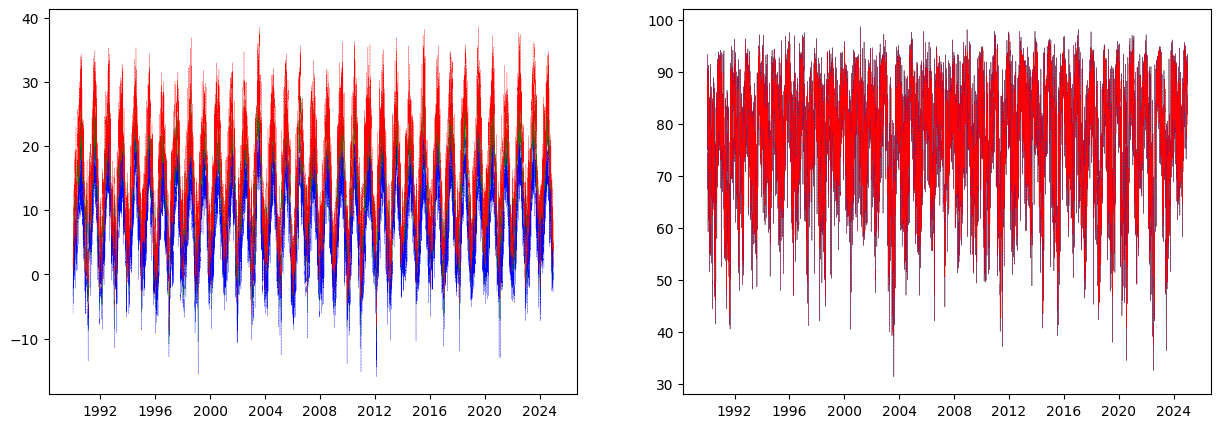

In [33]:
index = daily_dataRAW.index.values
dates = [datetime.date(year, month, day) for year, month, day in index]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
axes = axes.flatten()

axes[0].plot(dates, daily_dataRAW['Basel Temperature [2 m elevation corrected] MEAN'],'g', linewidth = .2)
axes[1].plot(dates, daily_dataRAW['Basel Relative Humidity [2 m] MEAN'],'g', linewidth = .2)

axes[0].plot(dates, daily_dataRAW['Basel Temperature [2 m elevation corrected] MIN'],'--b', linewidth = .2)
axes[1].plot(dates, daily_dataRAW['Basel Relative Humidity [2 m] MEAN'],'--b', linewidth = .2)

axes[0].plot(dates, daily_dataRAW['Basel Temperature [2 m elevation corrected] MAX'],'--r', linewidth = .2)
axes[1].plot(dates, daily_dataRAW['Basel Relative Humidity [2 m] MEAN'],'--r', linewidth = .2)
plt.show()

In [34]:
LR = 10e-5
EPOCHS = 50
opt = Adam(learning_rate=LR, decay=LR/EPOCHS)


model_myRNN = Sequential([
    SimpleRNN(256, return_sequences=True, input_shape=(31, 127), kernel_regularizer=regularizers.l2(0.001)),
    BatchNormalization(),
    Dropout(0.2),
    SimpleRNN(32, kernel_regularizer=regularizers.l2(0.001)),
    Dense(1270),
    Reshape((10, 127)),
]) 

model_myRNN.compile(optimizer=opt, loss='mse')
model_myRNN.summary()

Myhistory = model_myRNN.fit(
    X_train, 
    y_train, 
    epochs= EPOCHS, 
    batch_size= 32, 
    validation_data=(X_val, y_val), 
    callbacks=[
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
    ]
)


Model: "sequential_9"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn_8 (SimpleRNN)    (None, 31, 256)           98304     
                                                                 
 batch_normalization_11 (Bat  (None, 31, 256)          1024      
 chNormalization)                                                
                                                                 
 dropout_10 (Dropout)        (None, 31, 256)           0         
                                                                 
 simple_rnn_9 (SimpleRNN)    (None, 32)                9248      
                                                                 
 dense_18 (Dense)            (None, 1270)              41910     
                                                                 
 reshape_9 (Reshape)         (None, 10, 127)           0         
                                                      

In [35]:
Myprediction = model_myRNN.predict(toBePred)
MypredictionsDest = scaler.inverse_transform(np.array(Myprediction)[0, :, :])

MyTEMPandHumid = np.array(MypredictionsDest)[:,[0, 1]]

1/1 [==============================] - 0s 260ms/step


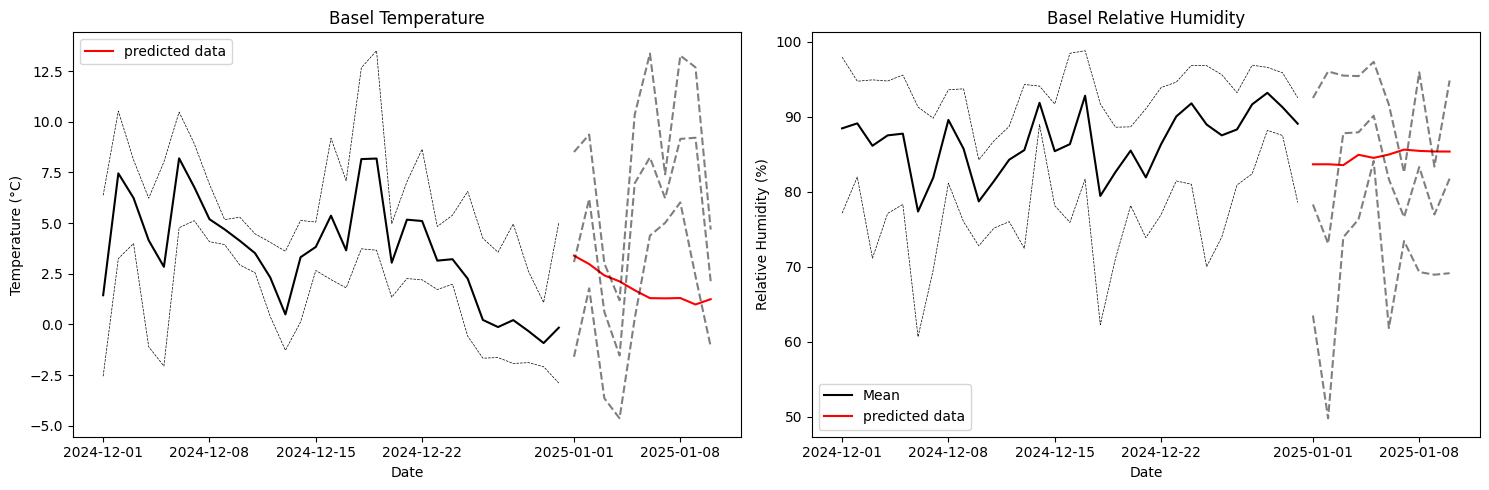

In [36]:
import datetime

index = daily_dataPRED.index.values
dates = [datetime.date(year, month, day) for year, month, day in index]

indexTrue = daily_true.index.values
datesPRED = [datetime.date(year, month, day) for year, month, day in indexTrue]


fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
axes = axes.flatten()

axes[0].plot(dates, daily_dataPRED['Basel Temperature [2 m elevation corrected] MEAN'], 'k')
axes[0].plot(dates, daily_dataPRED['Basel Temperature [2 m elevation corrected] MIN'], '--k', linewidth=0.5)
axes[0].plot(dates, daily_dataPRED['Basel Temperature [2 m elevation corrected] MAX'], '--k', linewidth=0.5)
axes[0].set_title('Basel Temperature')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Temperature (°C)')
axes[1].plot(dates, daily_dataPRED['Basel Relative Humidity [2 m] MEAN'], 'k', label='Mean')
axes[1].plot(dates, daily_dataPRED['Basel Relative Humidity [2 m] MIN'], '--k', linewidth=0.5)
axes[1].plot(dates, daily_dataPRED['Basel Relative Humidity [2 m] MAX'], '--k', linewidth=0.5)
axes[1].set_title('Basel Relative Humidity')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Relative Humidity (%)')

axes[0].plot(datesPRED, MyTEMPandHumid[:,0],'-r', label="predicted data")
axes[1].plot(datesPRED, MyTEMPandHumid[:,1],'-r', label="predicted data")

axes[0].plot(datesPRED, daily_true.values[:,0],'--k', alpha=.5)
axes[0].plot(datesPRED, daily_true.values[:,2],'--k', alpha=.5)
axes[0].plot(datesPRED, daily_true.values[:,4],'--k', alpha=.5)

axes[1].plot(datesPRED, daily_true.values[:,1],'--k', alpha=.5)
axes[1].plot(datesPRED, daily_true.values[:,3],'--k', alpha=.5)
axes[1].plot(datesPRED, daily_true.values[:,5],'--k', alpha=.5)

axes[0].legend()
axes[1].legend()

plt.tight_layout()
plt.show()

39/39 [==============================] - 0s 8ms/step - loss: 0.6895


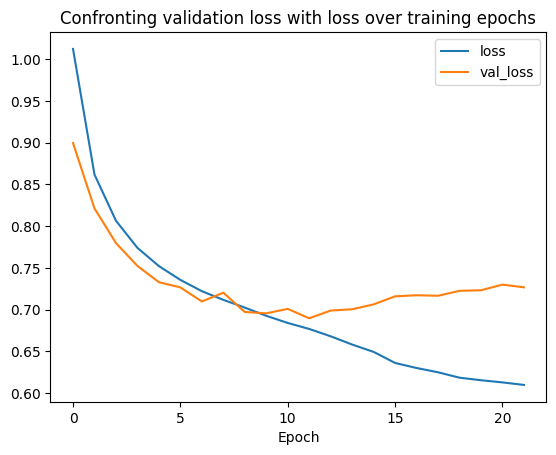

,Train Score,Test Score
sequential_9,0.665628,0.689538


In [37]:
for label in ["loss","val_loss"]:
    plt.plot(Myhistory.history[label],label=label)

plt.xlabel("Epoch")
plt.title("Confronting validation loss with loss over training epochs")

Score = pd.DataFrame(
    [[model_myRNN.evaluate(X_train, y_train), model_myRNN.evaluate(X_val, y_val)]],
    columns=["Train Score", "Test Score"], index=[model_myRNN.name]
)

plt.legend()
plt.show()

pd.DataFrame(Score)

# Final Remarks

If weather forecasting were to be performed using an ideal RNN, it would likely require a significantly more comprehensive feature set. Predictions of this nature are typically based on complex models that incorporate far more variables than the mean, maximum, and minimum of 44 atmospheric parameters.

The RNN I implemented tracked the provided data reasonably well, staying within an interval of 1.5×∣max−min∣/2 around the mean. However, it cannot be presented as a reliable weather forecast for temperature and humidity because the predictions deviate significantly from the observed values.

Extending the dataset to 30 years of historical data did not yield substantial improvements in the RNN's performance. My hypothesis, which could be explored through more advanced trials and a deeper review of the literature, is that the current feature space is insufficient. A more comprehensive dataset with additional, and likely more complex, atmospheric parameters would be necessary to capture the intricate patterns required for accurate weather predictions.

# References

1.  A. Géron (2019). *Hands-on Machine Learning with Scikit-Learn, Keras & TensorFlow Concepts, Tools, and Techniques to Build Intelligent Systems*. O'REILLY

2. Hands-on Machine Learning with Scikit-Learn, Keras & TensorFlow Concepts, Tools, and Techniques to Build Intelligent Systems

3. Tensorflow documentation. Retrieved from https://www.tensorflow.org/guide/keras

4. Keras documentation. Retrieved from https://keras.io/api/

4. Kaggle, "Simple RNN (weather prediction)" by Omkar Borade. Retrieved from https://www.kaggle.com/code/omkarborade/simple-rnn-weather-prediction

5. Machine Learning with Applications. Course's lectures. Carlo Barbieri. Retrieved from https://gitlab.com/cbarbieri/MachineLearning-con-applicazioni

6. Nketiah EA, Chenlong L, Yingchuan J, Aram SA. Recurrent neural network modeling of multivariate time series and its application in temperature forecasting. PLoS One. 2023 May 19;18(5):e0285713. doi: 10.1371/journal.pone.0285713. PMID: 37205720; PMCID: PMC10198567.